# Notebook 16 — Explainable AI (XAI) for Dengue Forecasting
## Interpreting the selected LSTM without changing the final test

**Research question:** Which historical input variables and months most influence the predictions of the **already selected** dengue forecasting model?

This notebook uses two complementary model-interpretation methods:

1. **Permutation importance:** how much validation MAE worsens when a feature's six-month trajectory is reassigned between validation observations.
2. **Integrated Gradients (IG):** which standardized feature values and time steps contribute to an individual model output relative to a reference sequence.

**Important distinction:** These are explanations of the trained model, **not proof that weather causes dengue**. No hyperparameters or features are changed based on these explanations. For independent test results, refer to Notebook 15; explanations are computed on **2022–2023 validation data**.

## 1. Research integrity and input meaning

Notebook 11 engineered historical dengue cases, lagged dengue cases, rolling statistics, temperature, humidity, rainfall, wind speed, and seasonal calendar features. Notebook 12 standardized these predictors using **training-only** statistics and built six-month sequences.

The model input is a tensor of shape `(number_of_examples, 6, number_of_features)`. The six rows correspond to consecutive feature months ending in month *t*, while the label is dengue cases in month *t+1*.

**Potential interpretability pitfalls:**
- Correlated features (e.g., rainfall and its rolling totals) share information, so individual importances can be unstable.
- Shuffling features produces some unrealistic combinations; importance estimates are **perturbation-based sensitivity**, not causal effects.
- Integrated Gradients depends on the chosen reference input and operates on the **log1p prediction**.
- Missing waste, sewage, and mosquito-surveillance variables cannot be attributed by this model because they are not input features.
- Validation data were already used in model selection. XAI is descriptive, not independent evidence of predictive skill.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error
from IPython.display import display

SEED = 42
RNG = np.random.default_rng(SEED)
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data" / "final" / "model_inputs").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Cannot locate model inputs. Open the Dengue_Project folder in VS Code.")
INPUT_DIR = ROOT / "data" / "final" / "model_inputs"
MODEL_DIR = ROOT / "models"
TABLE_DIR = ROOT / "results" / "tables"
FIG_DIR = ROOT / "results" / "figures"
METRIC_DIR = ROOT / "results" / "metrics"
for directory in (TABLE_DIR, FIG_DIR, METRIC_DIR):
    directory.mkdir(parents=True, exist_ok=True)
try:
    import tensorflow as tf
except ImportError as exc:
    raise ImportError("TensorFlow required: python -m pip install tensorflow") from exc
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Load the exact model selected by Notebook 15

We **do not** select a model again and **do not** read the 2024 test partition. Instead, we load Notebook 15's frozen validation-only selection manifest and the corresponding saved `.keras` model.

In [2]:
manifest_path = MODEL_DIR / "notebook15_final_model_selection.json"
if not manifest_path.is_file():
    raise FileNotFoundError("Run Notebook 15 first to freeze the model selection.")
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
assert manifest["dataset"] == "weather_only"
assert manifest["test_used_for_selection"] is False
selected_name = manifest["selected_model"]
assert selected_name in ("fixed_lstm", "gwo_lstm")
model_path = ROOT / manifest["selected_model_path"]
if not model_path.is_file():
    raise FileNotFoundError(f"Saved model not found: {model_path}. Model files may still be local/untracked in Git.")
model = tf.keras.models.load_model(model_path, compile=False)
print("Frozen model:", selected_name, "|", model_path.name)

Frozen model: gwo_lstm | notebook14_gwo_lstm_weather_only.keras


## 3. Load validation sequences and verify chronology

Permutation importance needs **observed validation labels**, so we use 2022–2023 only. Training inputs are used solely to construct the Integrated Gradients reference sequence; no fitting or model updating occurs.

In [3]:
def load_split(partition):
    npz_path = INPUT_DIR / f"weather_only_{partition}.npz"
    meta_path = INPUT_DIR / f"weather_only_{partition}_metadata.csv"
    with np.load(npz_path, allow_pickle=False) as pack:
        X = pack["X"].astype(np.float32)
        y = pack["y_raw"].astype(np.float64)
        features = pack["feature_names"].tolist()
    metadata = pd.read_csv(meta_path, parse_dates=["target_date", "feature_date"])
    assert len(X) == len(y) == len(metadata)
    assert metadata["partition"].eq(partition).all()
    assert np.isfinite(X).all() and np.isfinite(y).all()
    return X, y, features, metadata

X_val, y_val, names, val_meta = load_split("validation")
X_train, _, train_names, train_meta = load_split("train")
assert names == train_names
assert len(X_val) == 600 and X_val.shape[1] == 6
assert val_meta["target_date"].dt.year.isin([2022, 2023]).all()
assert train_meta["target_date"].max() <= pd.Timestamp("2021-12-01")
assert model.input_shape[-2:] == X_val.shape[1:]
assert len(names) == X_val.shape[-1]
print("Validation tensor:", X_val.shape)
print("Number of features:", len(names))
display(pd.DataFrame({"feature": names}).head(15))

Validation tensor: (600, 6, 33)
Number of features: 33


,feature
0,dengue_cases
1,dengue_cases_lag1
2,dengue_cases_lag2
3,dengue_cases_lag3
4,dengue_cases_lag6
5,dengue_cases_roll3_mean
6,dengue_cases_roll6_mean
7,temperature_mean_c
8,humidity_mean_percent
9,rainfall_total_mm


## 4. Reproduce the selected model's validation MAE

This is the reference against which permutation perturbations are compared. The network predicts `log1p(cases)`; convert predictions to original case units before computing MAE.

**Formula:** `permutation importance = MAE(shuffled input) − MAE(original input)`. A positive value means shuffling made the model worse, indicating sensitivity to that feature. Negative values are possible because of noise, correlations, or model behavior.

In [4]:
def predict_cases(X, batch_size=64):
    raw_log = model.predict(np.asarray(X, dtype=np.float32), batch_size=batch_size, verbose=0)
    return np.maximum(0.0, np.expm1(np.clip(np.asarray(raw_log, dtype=np.float64).reshape(-1), -20.0, 20.0)))

reference_predictions = predict_cases(X_val)
reference_mae = float(mean_absolute_error(y_val, reference_predictions))
print("Selected model validation MAE (cases):", round(reference_mae, 4))
print("This is NOT an independent test metric.")

Selected model validation MAE (cases): 85.0649
This is NOT an independent test metric.


## 5. Permutation importance — step-by-step

**Example:** To test `rainfall_total_mm`, take its six consecutive values in each validation sequence. Shuffle these **whole trajectories** between validation examples, leaving other features untouched. Predict again and calculate how much MAE changes.

To limit confounding from calendar season, trajectories are shuffled **within the same target calendar month** (e.g., among January predictions only). This preserves the seasonal group but breaks relationships between weather trajectories and other predictors. It does **not** preserve all physical correlations.

We use a fixed random seed and **two repetitions** by default. Increase repetitions to 5–10 for a more stable paper-quality estimate, at the cost of more inference time. All permutations are **post-training analysis**; the model is never refitted.

In [5]:
N_REPEATS = 2   # Increase to 5–10 for a more stable research report.
assert N_REPEATS >= 1
month_groups = [idx.to_numpy() for _, idx in val_meta.groupby(val_meta["target_date"].dt.month).groups.items()]
assert sum(len(idx) for idx in month_groups) == len(X_val)

def permuted_mae(feature_indices, rng):
    shuffled = X_val.copy()
    # Shuffle whole 6-month trajectories across observations with the same target month.
    for idx in month_groups:
        if len(idx) < 2:
            continue
        order = rng.permutation(idx)
        shuffled[np.ix_(idx, np.arange(X_val.shape[1]), feature_indices)] = X_val[np.ix_(order, np.arange(X_val.shape[1]), feature_indices)]
    return float(mean_absolute_error(y_val, predict_cases(shuffled)))

importance_rows = []
for j, feature in enumerate(names):
    perturbed = [permuted_mae([j], RNG) for _ in range(N_REPEATS)]
    importance_rows.append({
        "feature": feature, "validation_MAE_original_cases": reference_mae,
        "mean_permuted_MAE_cases": float(np.mean(perturbed)),
        "importance_delta_MAE_cases": float(np.mean(perturbed) - reference_mae),
        "std_permuted_MAE_cases": float(np.std(perturbed, ddof=1)) if N_REPEATS > 1 else 0.0,
        "repeats": N_REPEATS,
    })
feature_importance = pd.DataFrame(importance_rows).sort_values("importance_delta_MAE_cases", ascending=False).reset_index(drop=True)
display(feature_importance.head(15).round(4))

,feature,validation_MAE_original_cases,mean_permuted_MAE_cases,importance_delta_MAE_cases,std_permuted_MAE_cases,repeats
0,dengue_cases,85.0649,124.3204,39.2555,1.4321,2
1,dengue_cases_roll3_mean,85.0649,97.1977,12.1328,2.4398,2
2,humidity_mean_percent,85.0649,87.2733,2.2085,0.1713,2
3,humidity_mean_percent_lag3,85.0649,86.9670,1.9022,0.0495,2
4,wind_speed_mean_kmh_lag2,85.0649,86.8377,1.7729,0.1332,2
5,wind_speed_mean_kmh_lag1,85.0649,86.6347,1.5699,0.8272,2
6,humidity_mean_percent_lag1,85.0649,86.5667,1.5018,0.9266,2
7,temperature_mean_c,85.0649,86.5180,1.4532,0.7808,2
8,wind_speed_mean_kmh_roll3_mean,85.0649,86.4369,1.3720,0.4672,2
9,dengue_cases_lag1,85.0649,86.4212,1.3564,1.6507,2


## 6. Explain by feature family

The individual features are strongly correlated, so we also perturb them as **groups**. The categories come from the actual engineered feature names:

- **Historical dengue:** current and lagged dengue case counts, rolling dengue statistics.
- **Weather:** temperature, humidity, rainfall, wind speed, and their lagged/rolling versions.
- **Seasonality:** sine/cosine encoding of the target month.

Group importance can differ substantially from the sum of individual feature importances. This is expected with correlated predictors.

,feature_family,n_features,importance_delta_MAE_cases,mean_permuted_MAE_cases,repeats
0,historical_dengue,7,75.8071,160.8720,2
1,weather,24,13.3815,98.4464,2
2,seasonality,2,0.0000,85.0649,2


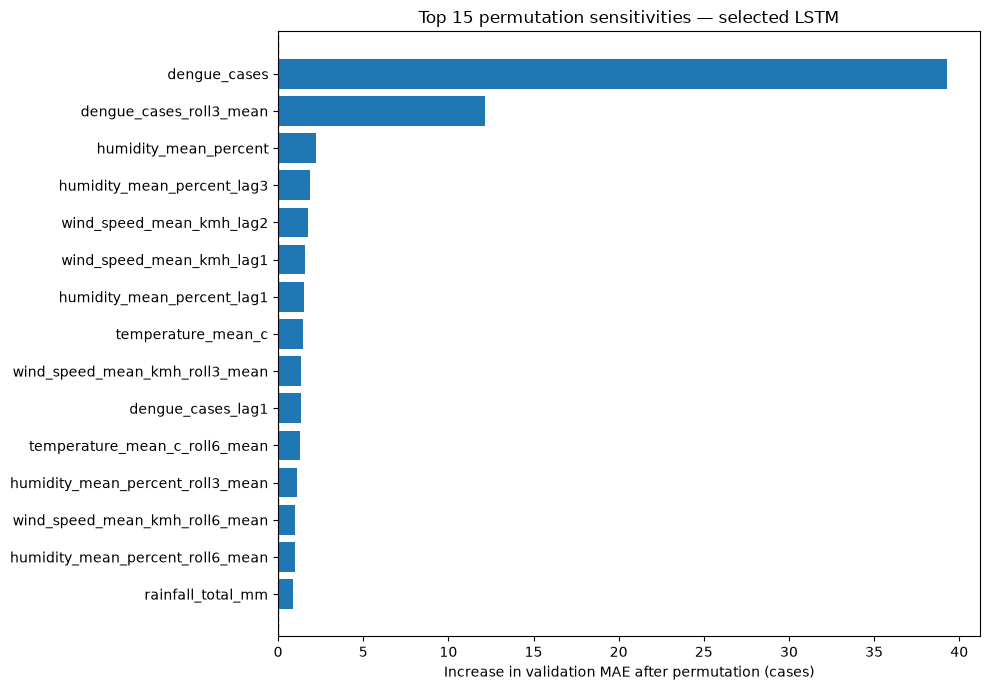

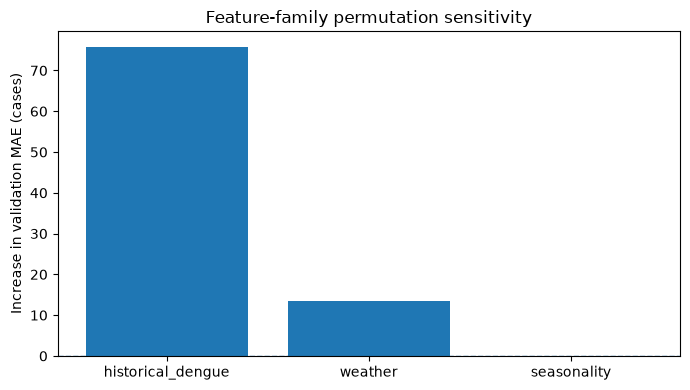

In [6]:
def feature_family(feature):
    if feature.startswith("dengue_cases"):
        return "historical_dengue"
    if feature.startswith("target_month_"):
        return "seasonality"
    return "weather"

families = {key: [i for i, name in enumerate(names) if feature_family(name) == key]
            for key in ("historical_dengue", "weather", "seasonality")}
assert all(len(indices) > 0 for indices in families.values())
assert sorted(i for values in families.values() for i in values) == list(range(len(names)))
group_rows = []
for group, indices in families.items():
    values = [permuted_mae(indices, RNG) for _ in range(N_REPEATS)]
    group_rows.append({"feature_family": group, "n_features": len(indices),
                       "importance_delta_MAE_cases": float(np.mean(values) - reference_mae),
                       "mean_permuted_MAE_cases": float(np.mean(values)), "repeats": N_REPEATS})
group_importance = pd.DataFrame(group_rows).sort_values("importance_delta_MAE_cases", ascending=False)
display(group_importance.round(4))

plot_data = feature_importance.head(15).sort_values("importance_delta_MAE_cases")
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(plot_data["feature"], plot_data["importance_delta_MAE_cases"])
ax.axvline(0, linestyle="--", linewidth=1)
ax.set(xlabel="Increase in validation MAE after permutation (cases)", title="Top 15 permutation sensitivities — selected LSTM")
fig.tight_layout()
fig.savefig(FIG_DIR / "notebook16_permutation_feature_importance.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(group_importance["feature_family"], group_importance["importance_delta_MAE_cases"])
ax.axhline(0, linestyle="--", linewidth=1)
ax.set(ylabel="Increase in validation MAE (cases)", title="Feature-family permutation sensitivity")
fig.tight_layout()
fig.savefig(FIG_DIR / "notebook16_permutation_group_importance.png", dpi=160)
plt.show()

## 7. Integrated Gradients (IG): local explanations

Permutation importance is **global**: it measures average sensitivity over the validation set. Integrated Gradients is **local**: it attributes the output of one prediction to each of the six time steps and each feature.

For input sequence **x**, reference sequence **b**, and model output **F**:

\[\mathrm{IG}_i(x) = (x_i-b_i)\int_0^1 \frac{\partial F(b+\alpha(x-b))}{\partial x_i}\,d\alpha.\]

We approximate the integral using 64 equally spaced interpolation points. The reference is the **average of training sequences**, not a 2024 observation. IG is computed in standardized-feature units for the **log1p(cases) model output**. The attribution sum approximately equals `F(x) − F(b)`; the equality becomes closer with more integration steps.

This is not a causal attribution. A synthetic mean sequence may not represent a physically realizable weather history.

In [7]:
reference_sequence = np.mean(X_train, axis=0).astype(np.float32)
assert reference_sequence.shape == X_val.shape[1:]

def integrated_gradients(sequence, baseline, steps=64):
    x = tf.convert_to_tensor(np.asarray(sequence, dtype=np.float32))
    b = tf.convert_to_tensor(np.asarray(baseline, dtype=np.float32))
    assert tuple(x.shape) == tuple(b.shape)
    alphas = tf.linspace(0.0, 1.0, steps + 1)
    interpolated = b[None, :, :] + alphas[:, None, None] * (x - b)[None, :, :]
    with tf.GradientTape() as tape:
        tape.watch(interpolated)
        output = tf.reshape(model(interpolated, training=False), (-1,))
    grads = tape.gradient(output, interpolated)
    if grads is None:
        raise RuntimeError("Model gradients unavailable; check model differentiability.")
    mean_grads = tf.reduce_mean((grads[:-1] + grads[1:]) / 2.0, axis=0)
    attr = (x - b) * mean_grads
    fx = float(tf.reshape(model(x[None, :, :], training=False), (-1,))[0].numpy())
    fb = float(tf.reshape(model(b[None, :, :], training=False), (-1,))[0].numpy())
    return attr.numpy(), fx, fb

# Choose three representative validation examples without looking at test labels:
# lowest, median and highest observed validation dengue cases.
ordered = np.argsort(y_val)
example_indices = [int(ordered[0]), int(ordered[len(ordered) // 2]), int(ordered[-1])]
local_records = []
local_attrs = {}
for tag, idx in zip(("low", "median", "high"), example_indices):
    attr, fx, fb = integrated_gradients(X_val[idx], reference_sequence, steps=64)
    local_attrs[tag] = attr
    local_records.append({
        "example": tag, "validation_index": idx,
        "district": str(val_meta.iloc[idx]["administrative_district"]),
        "target_date": str(val_meta.iloc[idx]["target_date"].date()),
        "observed_cases": float(y_val[idx]),
        "predicted_cases": float(predict_cases(X_val[idx:idx+1])[0]),
        "predicted_log1p": fx, "baseline_log1p": fb,
        "IG_sum": float(attr.sum()),
        "IG_completeness_difference": float(attr.sum() - (fx - fb)),
    })
local_summary = pd.DataFrame(local_records)
display(local_summary.round(4))

,example,validation_index,district,target_date,observed_cases,predicted_cases,predicted_log1p,baseline_log1p,IG_sum,IG_completeness_difference
0,low,584,Vavuniya,2022-09-01,0.0000,9.3960,2.3414,4.7801,-2.4386,0.0001
1,median,395,Matara,2022-12-01,112.7143,134.2004,4.9068,4.7801,0.1266,-0.0001
2,high,215,Jaffna,2023-12-01,2392.0000,624.6104,6.4387,4.7801,1.6587,0.0001


## 8. Visualize attribution across six months

The heatmap shows **signed** IG contributions for the 12 features with the largest absolute attribution for the high-case validation example. Positive values push the model's log1p output above the reference; negative values push it below.

The time-step plot sums absolute attributions across features at each of the six months. This indicates where the model is most sensitive **for this example only**; it does not prove that a specific biological lag causes dengue.

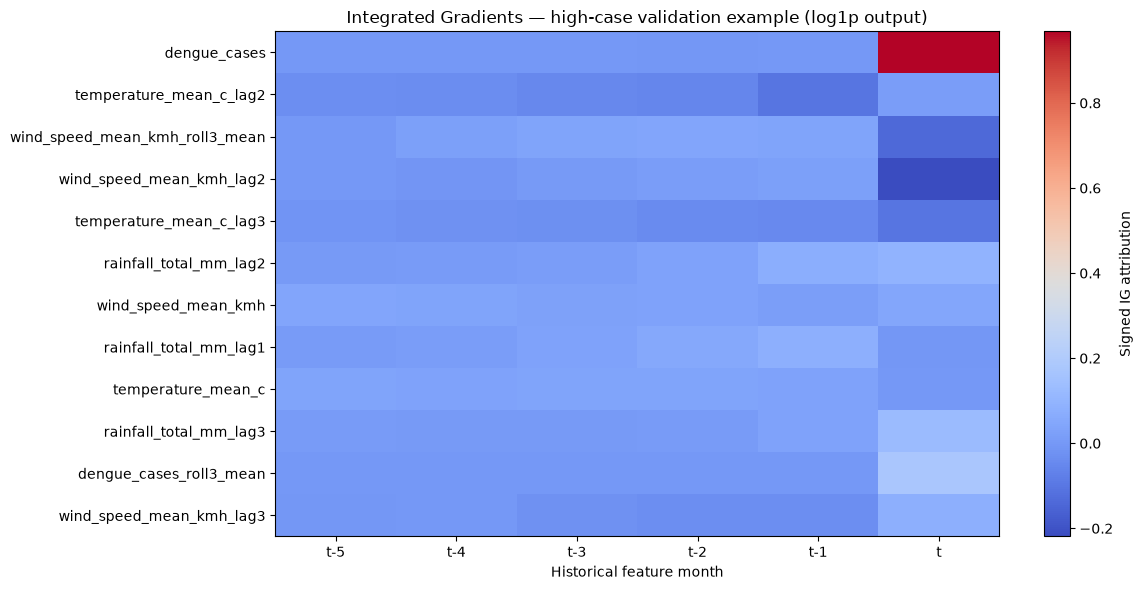

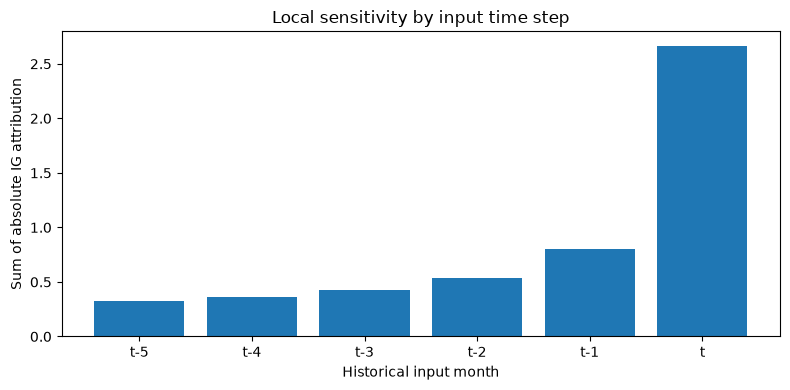

In [8]:
attr = local_attrs["high"]
top_indices = np.argsort(np.sum(np.abs(attr), axis=0))[-12:][::-1]
fig, ax = plt.subplots(figsize=(12, 6))
image = ax.imshow(attr[:, top_indices].T, aspect="auto", cmap="coolwarm")
ax.set_yticks(range(len(top_indices)), [names[i] for i in top_indices])
ax.set_xticks(range(6), ["t-5", "t-4", "t-3", "t-2", "t-1", "t"])
ax.set(xlabel="Historical feature month", title="Integrated Gradients — high-case validation example (log1p output)")
fig.colorbar(image, ax=ax, label="Signed IG attribution")
fig.tight_layout()
fig.savefig(FIG_DIR / "notebook16_integrated_gradients_heatmap.png", dpi=160)
plt.show()

lag_sensitivity = np.sum(np.abs(attr), axis=1)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(["t-5", "t-4", "t-3", "t-2", "t-1", "t"], lag_sensitivity)
ax.set(xlabel="Historical input month", ylabel="Sum of absolute IG attribution", title="Local sensitivity by input time step")
fig.tight_layout()
fig.savefig(FIG_DIR / "notebook16_integrated_gradients_timesteps.png", dpi=160)
plt.show()

## 9. Save XAI research artifacts

The tables preserve exact numeric outputs so that plots can be regenerated and claims checked. The full local attribution table contains one row per example, feature, and time step. `notebook16_xai_methodology.json` documents settings and limitations.

In [9]:
local_attribution_rows = []
for tag, attr in local_attrs.items():
    for time_step in range(attr.shape[0]):
        for j, name in enumerate(names):
            local_attribution_rows.append({
                "example": tag, "input_step": time_step,
                "relative_month": f"t-{5-time_step}" if time_step < 5 else "t",
                "feature": name, "IG_log1p_attribution": float(attr[time_step, j]),
            })
local_attributions = pd.DataFrame(local_attribution_rows)
outputs = {
    "notebook16_permutation_feature_importance.csv": feature_importance,
    "notebook16_permutation_group_importance.csv": group_importance,
    "notebook16_ig_local_summary.csv": local_summary,
    "notebook16_ig_local_attributions.csv": local_attributions,
}
for name, frame in outputs.items():
    frame.to_csv(TABLE_DIR / name, index=False)
    print("Saved", name, "rows:", len(frame))
methodology = {
    "selected_model": selected_name,
    "model_path": str(model_path.relative_to(ROOT)),
    "analysis_period": "validation_2022_2023_only",
    "test_data_used_for_xai": False,
    "reference_validation_MAE_cases": reference_mae,
    "permutation_repeats": N_REPEATS,
    "permutation_unit": "whole_six_month_trajectory_within_same_target_calendar_month",
    "permutation_seed": SEED,
    "integrated_gradients_steps": 64,
    "integrated_gradients_reference": "mean_of_training_sequences",
    "integrated_gradients_output_scale": "log1p_cases",
    "cautions": ["Model sensitivity is not causal effect.",
                 "Correlated predictors make feature rankings unstable.",
                 "Permuted inputs may be physically implausible.",
                 "XAI was not used to retune the frozen final model."],
}
(METRIC_DIR / "notebook16_xai_methodology.json").write_text(json.dumps(methodology, indent=2), encoding="utf-8")
assert len(feature_importance) == len(names)
assert len(local_attributions) == len(local_attrs) * 6 * len(names)
assert np.isfinite(local_attributions["IG_log1p_attribution"]).all()
print("ALL NOTEBOOK 16 CHECKS PASSED — model unchanged; 2024 test not accessed.")

Saved notebook16_permutation_feature_importance.csv rows: 33
Saved notebook16_permutation_group_importance.csv rows: 3
Saved notebook16_ig_local_summary.csv rows: 3
Saved notebook16_ig_local_attributions.csv rows: 594
ALL NOTEBOOK 16 CHECKS PASSED — model unchanged; 2024 test not accessed.


## 10. How to write your findings

After running on real data, answer these questions using **actual saved numbers**:

1. Which features have the largest **positive** permutation importance? Report the delta in validation MAE (case units) and the number of repetitions.
2. Is the model more sensitive to **historical dengue**, **weather**, or **seasonality** when those features are permuted as groups?
3. For the selected high-case validation example, which inputs and time steps contribute positively or negatively to the **log1p** prediction?
4. Is the Integrated Gradients completeness difference reasonably small? Increase integration steps if necessary.
5. Explain limitations: correlated predictors, artificial perturbations, the baseline choice, absence of waste/sewage/mosquito data, and the lack of causal identification.

**Final scientific distinction:** Notebook 15 evaluates generalization on 2024. Notebook 16 explains how the **frozen selected model** behaves on development-period validation data. It does **not** produce a new or better model.